# PyPSA network summaries

Per-scenario capacity and cost summaries produced by the `build_pypsa_summary`
rule (`build/pypsa/<scenario>/summary.csv`, rows indexed by technology machine
key). Three charts, each one stacked bar per scenario with one colour per
technology. Display names and colours come from `technology_info` in
`config/default.yaml`, keyed by the same machine key, so the config is the
single source of truth for naming and colour.

1. **Power capacity (GW)** — hatched = brownfield (already installed), solid =
   expanded (new build); the full bar height is the final capacity.
2. **Storage energy capacity (TWh)** — same encoding, for the storage
   technologies.
3. **Costs (bn€)** — solid = expanded capex, hatched = opex.

Each bar also carries, in greys above the coloured technologies, the network
carriers that no `technology_info` entry claims — the largest few by name, the
rest lumped into one segment (`pypsa.unmapped_display` in the config sets how
many). They measure the coverage of the metal accounting: grey height is
network activity the technology rows do not see. Some grey is expected and
harmless (fuel and CO₂ carriers that consume no metals); some is a genuine gap.
Unclassified carriers have no `electrical_input` flag, so input-side ones stack
below the zero line rather than being sign-corrected.

A technology or carrier that is all-zero in a chart is dropped from that
chart's bars and legend, so the three charts show different subsets.
Technologies whose `capacity_source` is not `pypsa_eur` (`grid`, `ev_battery`,
`ev_motor`) are absent from PyPSA by construction and so never appear.

Run by the `visualise_pypsa` snakemake rule, or interactively (paths then
resolve relative to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import numpy as np
import xarray as xr
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above

try:
    paths = dict(
        combined=snakemake.input.combined,  # noqa: F821 — injected by the snakemake notebook rule
        combined_unmapped=snakemake.input.combined_unmapped,  # noqa: F821
        figures=snakemake.output.figures,  # noqa: F821
    )
    technology_info = dict(snakemake.params.technology_info)  # noqa: F821
    unmapped_display = dict(snakemake.params.unmapped_display)  # noqa: F821
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    unmapped_display = config["pypsa"]["unmapped_display"]
    style = config["plotting"]
    paths = dict(
        combined=repo / "build/pypsa/all_scenarios.nc",
        combined_unmapped=repo / "build/pypsa/all_scenarios_unmapped_carriers.nc",
        figures=repo / "build/pypsa/figures",
    )

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]

# Machine key -> display name / colour, in config order (sets stack + legend order).
technologies = list(technology_info)
nice_names = {t: technology_info[t]["nice_name"] for t in technologies}
colors = {t: technology_info[t]["color"] for t in technologies}

# Unmapped carriers are keyed by their raw PyPSA name, so they need no nice
# name; only the lumped remainder does. Sentinel key cannot collide with a real
# carrier because PyPSA carrier names never contain a slash.
UNMAPPED_OTHER = "other/unmapped"
UNMAPPED_TOP_N = unmapped_display["top_n"]
UNMAPPED_COLORS = list(unmapped_display["colors"])
if UNMAPPED_TOP_N > len(UNMAPPED_COLORS):
    raise ValueError(
        f"unmapped_display.top_n is {UNMAPPED_TOP_N} but only "
        f"{len(UNMAPPED_COLORS)} colors are configured; add one colour per "
        "individually-named carrier."
    )
nice_names[UNMAPPED_OTHER] = unmapped_display["other_nice_name"]
colors[UNMAPPED_OTHER] = unmapped_display["other_color"]

In [2]:
# Combined summaries built by rule create_pypsa_summary: dims (scenario,
# technology), one data variable per capacity / cost metric. Back to the
# (scenario, technology) frame the plots below expect.
summaries = xr.open_dataset(paths["combined"])
data = summaries.to_dataframe()
scenarios = list(summaries["scenario"].values)

# Same metrics, but for the carriers no technology_info entry claims.
unmapped_data = xr.open_dataset(paths["combined_unmapped"]).to_dataframe()
summaries

<xarray.Dataset> Size: 15kB
Dimensions:                          (scenario: 7, technology: 19)
Coordinates:
  * scenario                         (scenario) <U16 448B 'base' ... 'v2g'
  * technology                       (technology) <U17 1kB 'nuclear' ... 'ev_...
Data variables:
    expanded_capex_bn€               (scenario, technology) float64 1kB 0.0 ....
    opex_bn€                         (scenario, technology) float64 1kB 15.12...
    brownfield_cap_gw                (scenario, technology) float64 1kB 112.5...
    final_cap_gw                     (scenario, technology) float64 1kB 112.5...
    expanded_cap_gw                  (scenario, technology) float64 1kB 0.0 ....
    brownfield_cap_twh               (scenario, technology) float64 1kB nan ....
    final_cap_twh                    (scenario, technology) float64 1kB nan ....
    expanded_cap_twh                 (scenario, technology) float64 1kB nan ....
    route_length_km                  (scenario, technology) float64 1kB nan ....
    brownfield_capacity_length_gwkm  (scenario, technology) float64 1kB nan ....
    final_capacity_length_gwkm       (scenario, technology) float64 1kB nan ....
    expanded_capacity_length_gwkm    (scenario, technology) float64 1kB nan ....

In [3]:
BAR_WIDTH = 0.6
HATCH = "///"


def hatch_color(fill):
    """Dark hatch on light fills, white hatch on dark fills."""
    r, g, b = mcolors.to_rgb(fill)
    return ink["secondary"] if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else ink["surface"]


def unmapped_frames(metrics, colors, nice_names):
    """Per-metric scenario x carrier frames for the unmapped carriers, reduced
    to the `top_n` largest plus one lumped remainder.

    Ranking is by total absolute value across every metric in this chart, so
    each chart names the carriers that actually matter to it. Mutates the
    passed `colors` / `nice_names` to register the carriers it kept.
    """
    frames = [
        unmapped_data[metric].unstack("carrier").reindex(index=scenarios).fillna(0.0)
        for metric in metrics
    ]
    magnitude = sum(frame.abs().sum() for frame in frames)
    ranked = list(magnitude[magnitude > 0].sort_values(ascending=False).index)
    named, lumped = ranked[:UNMAPPED_TOP_N], ranked[UNMAPPED_TOP_N:]

    for carrier, color in zip(named, UNMAPPED_COLORS):
        colors[carrier] = color
        nice_names[carrier] = carrier
    reduced = [
        frame[named].assign(**{UNMAPPED_OTHER: frame[lumped].sum(axis=1)})
        for frame in frames
    ]
    return named + [UNMAPPED_OTHER], reduced


def stacked_by_technology(segments, unit, segment_labels, name):
    """One stacked bar per scenario; each technology contributes its segments
    (drawn bottom-up in the given order) in the technology's colour, hatched
    segments overlaid with a diagonal texture. Negative values (e.g. the tiny
    negative heat-pump opex) stack below zero.

    Carriers outside technology_info are appended after the technologies, in
    greys, so each bar shows its whole network total and how much of it the
    metal accounting does not cover.

    No title is drawn: the caption is written where the figure is published.

    segments: list of (metric column name, hatched: bool)
    segment_labels: (solid_label, hatched_label) for the segment-meaning
        legend, or None for a single-metric chart with nothing to explain
    name: what to write the figure as, without a suffix
    """
    metrics = [metric for metric, _ in segments]
    hatched = [h for _, h in segments]

    # Local copies: the unmapped ranking is per chart, so the carrier colours
    # it assigns must not leak into the next chart's legend.
    chart_colors = dict(colors)
    chart_nice_names = dict(nice_names)
    unmapped_keys, unmapped = unmapped_frames(metrics, chart_colors, chart_nice_names)

    frames = [
        data[metric]
        .unstack("technology")
        .reindex(index=scenarios, columns=technologies)
        .fillna(0.0)
        .join(unmapped_frame)
        for metric, unmapped_frame in zip(metrics, unmapped)
    ]
    keys = technologies + unmapped_keys
    present = [k for k in keys if any((f[k].abs() > 0).any() for f in frames)]

    # The key hangs off the right: two dozen carriers are as tall as the bars,
    # so under the panel they would cost more page than they are worth.
    fig, (ax,) = plotting.page_figure(style)
    x = np.arange(len(scenarios))
    pos = np.zeros(len(scenarios))
    neg = np.zeros(len(scenarios))
    for key in present:
        for frame, is_hatched in zip(frames, hatched):
            values = frame[key].to_numpy()
            bottom = np.where(values >= 0, pos, neg)
            ax.bar(
                x, values, BAR_WIDTH, bottom=bottom,
                color=chart_colors[key], edgecolor=style["bar"]["edge_color"],
                linewidth=style["bar"]["edge_width"],
            )
            if is_hatched:
                ax.bar(
                    x, values, BAR_WIDTH, bottom=bottom,
                    facecolor="none", hatch=HATCH, linewidth=0,
                    edgecolor=hatch_color(chart_colors[key]),
                )
            pos += np.clip(values, 0, None)
            neg += np.clip(values, None, 0)

    totals = pos + neg
    for i, total in enumerate(totals):
        ax.text(x[i], pos[i] + 0.015 * pos.max(), f"{total:,.0f}",
                ha="center", va="bottom", color=ink["secondary"])

    plotting.style_panel(ax, style, title=None, ylabel=unit)
    plotting.category_axis(
        ax,
        {scenario: float(i) for i, scenario in enumerate(scenarios)},
        {scenario: scenario for scenario in scenarios},
        style,
    )
    ax.set_ylim(min(0.0, 1.05 * neg.min()), 1.1 * pos.max())
    if neg.min() < 0:
        ax.axhline(0, color=ink["secondary"], linewidth=0.8)

    # Legend top-down matches the stack top-down.
    tech_legend = fig.legend(
        handles=plotting.patch_handles(
            reversed(present), chart_colors, chart_nice_names
        ),
        title="Technology / unmapped carrier", frameon=False,
        loc="outside right upper",
    )
    # A single-metric chart (e.g. route length) has nothing solid-vs-hatched
    # to explain, so it passes segment_labels=None and gets no Segment legend.
    if segment_labels is not None:
        solid_label, hatched_label = segment_labels
        segment_legend = fig.legend(
            handles=[
                mpatches.Patch(facecolor=ink["grid"], label=solid_label),
                mpatches.Patch(facecolor=ink["grid"], hatch=HATCH,
                               edgecolor=ink["secondary"], linewidth=0,
                               label=hatched_label),
            ],
            # Below the axes, not in the right margin: the technology legend
            # varies in height with how many entries a chart keeps, and would
            # otherwise overlap this one.
            title="Segment", frameon=False, ncol=2,
            loc="outside lower left",
        )
        legends = (tech_legend, segment_legend)
    else:
        legends = (tech_legend,)

    # Both legends are figure-level artists sitting outside the axes, so
    # `save_figure` has to be told about them or the tight crop drops them.
    plotting.save_figure(fig, figures_dir, name, style, legends)
    # No return: the inline backend displays the open figure once at cell end;
    # returning it as well would render each figure twice.

## Power capacity

Full bar height per technology = final capacity; the hatched base is what was
already installed (brownfield), the solid remainder is optimised expansion.

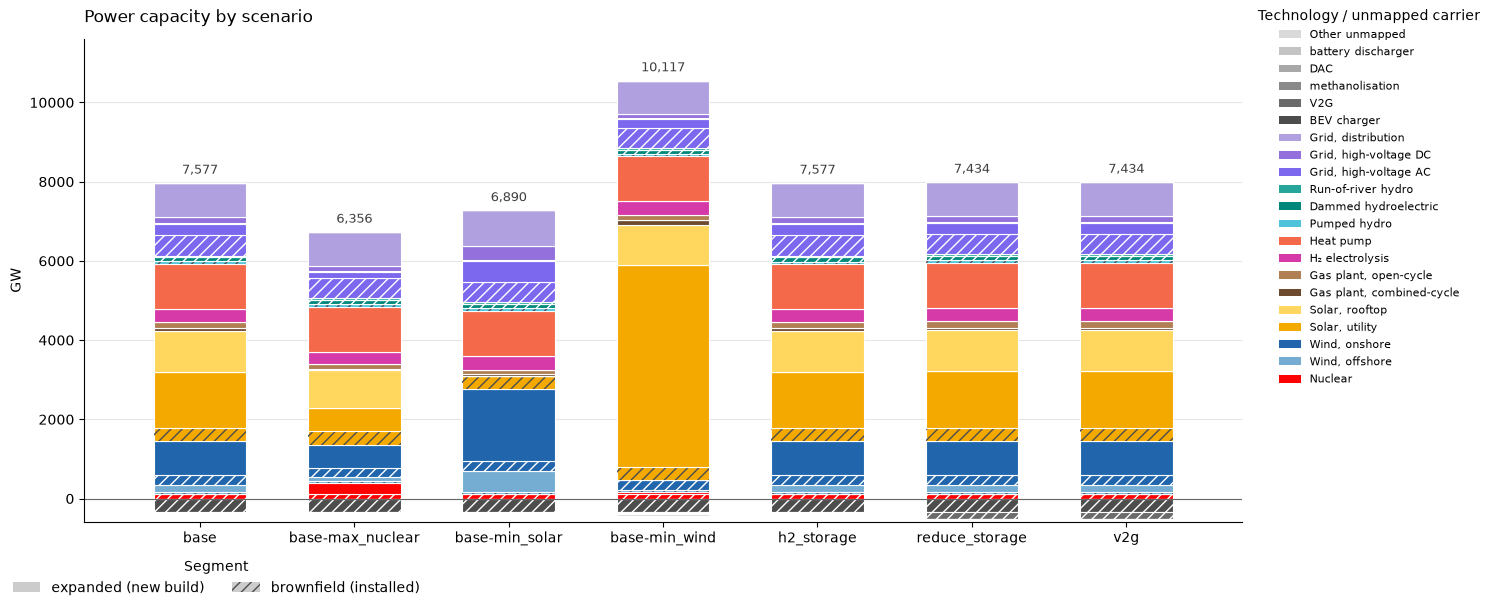

In [4]:
stacked_by_technology(
    segments=[
        ("brownfield_cap_gw", True),
        ("expanded_cap_gw", False),
    ],
    unit="GW",
    segment_labels=("Expanded (new build)", "Brownfield (installed)"),
    name="capacity_power_gw",
)

## Storage energy capacity

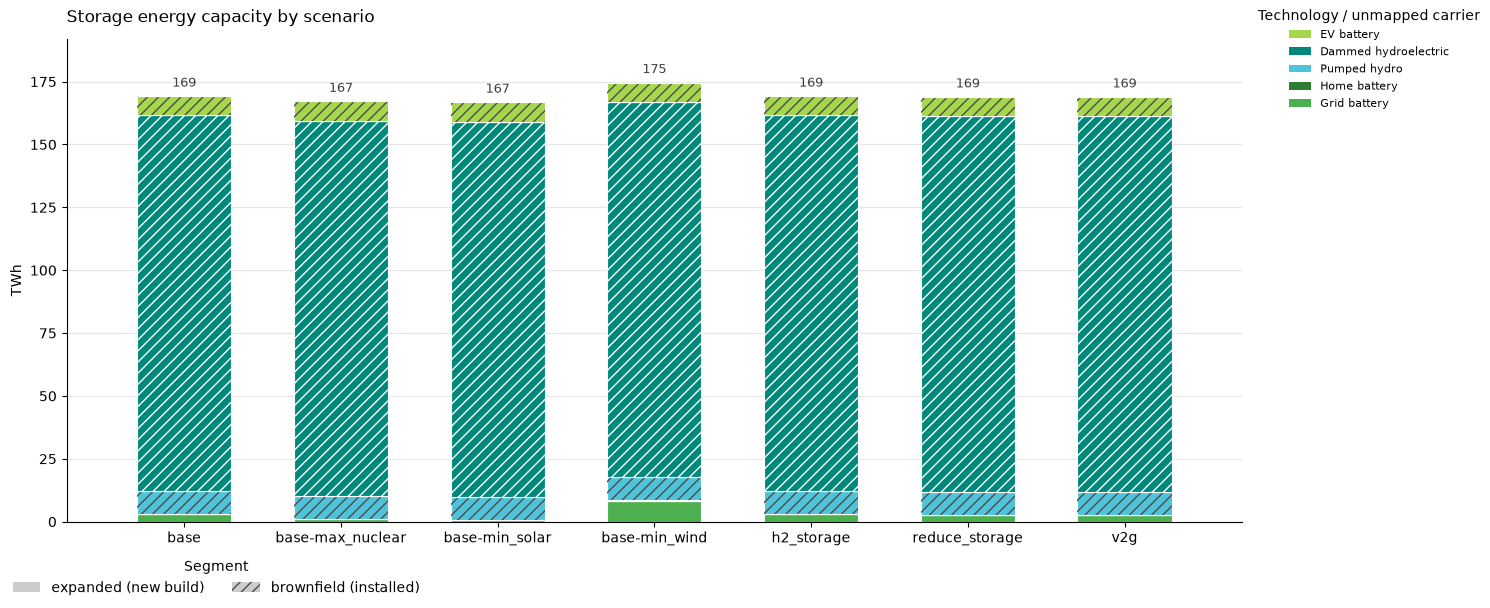

In [5]:
stacked_by_technology(
    segments=[
        ("brownfield_cap_twh", True),
        ("expanded_cap_twh", False),
    ],
    unit="TWh",
    segment_labels=("Expanded (new build)", "Brownfield (installed)"),
    name="capacity_storage_twh",
)

## Transmission capacity-length

AC and DC lines carry a capacity-length (GW·km) on top of a power rating, and
the grid inventories scale with it. Full bar = final GW·km; the hatched base is
the brownfield network, the solid remainder the optimised reinforcement. Only
the two transmission carriers have a length — the distribution link and every
generation technology contribute nothing here.

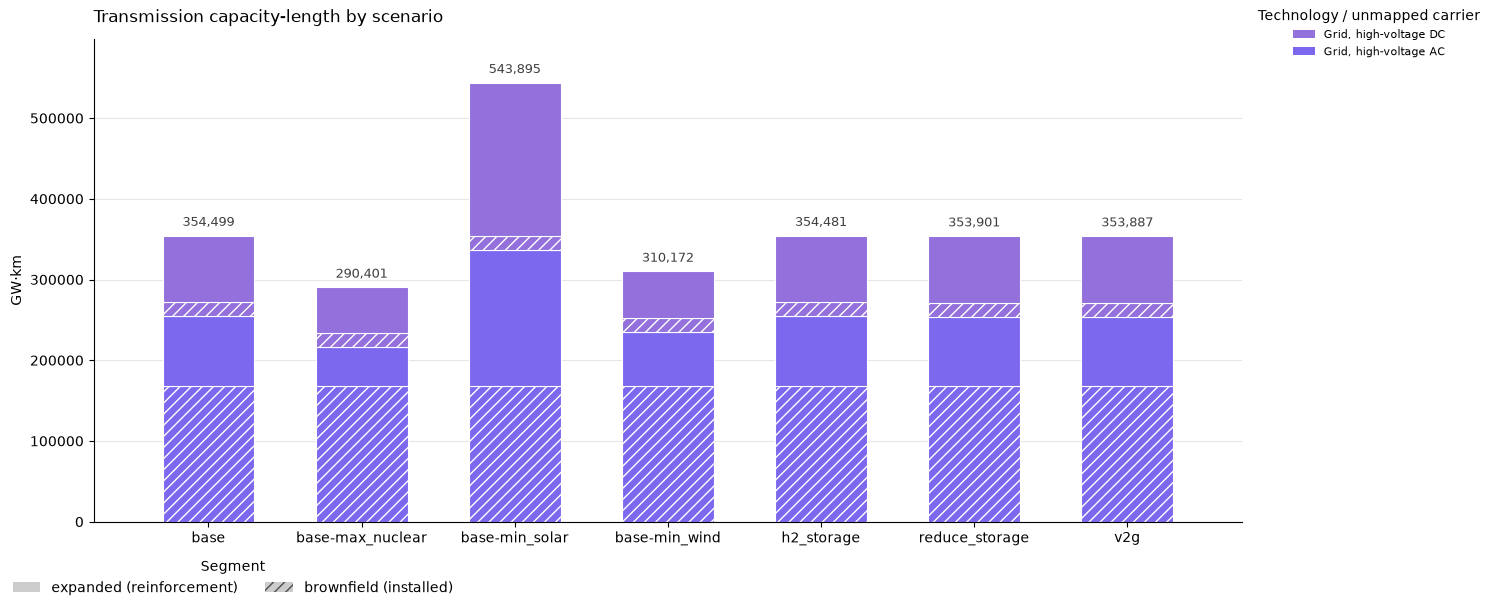

In [6]:
stacked_by_technology(
    segments=[
        ("brownfield_capacity_length_gwkm", True),
        ("expanded_capacity_length_gwkm", False),
    ],
    unit="GW·km",
    segment_labels=("Expanded (reinforcement)", "Brownfield (installed)"),
    name="capacity_length_gwkm",
)

## Transmission route length

Route length is a property of the topology, not the solve: PyPSA-Eur reinforces
existing corridors instead of adding new ones, so each carrier has a single
route-length figure and reinforcement shows up in the GW·km chart above rather
than here. It is near-constant across scenarios — DC covers its whole candidate
corridor set — so the bars mainly show the AC-vs-DC split of the modelled routes.

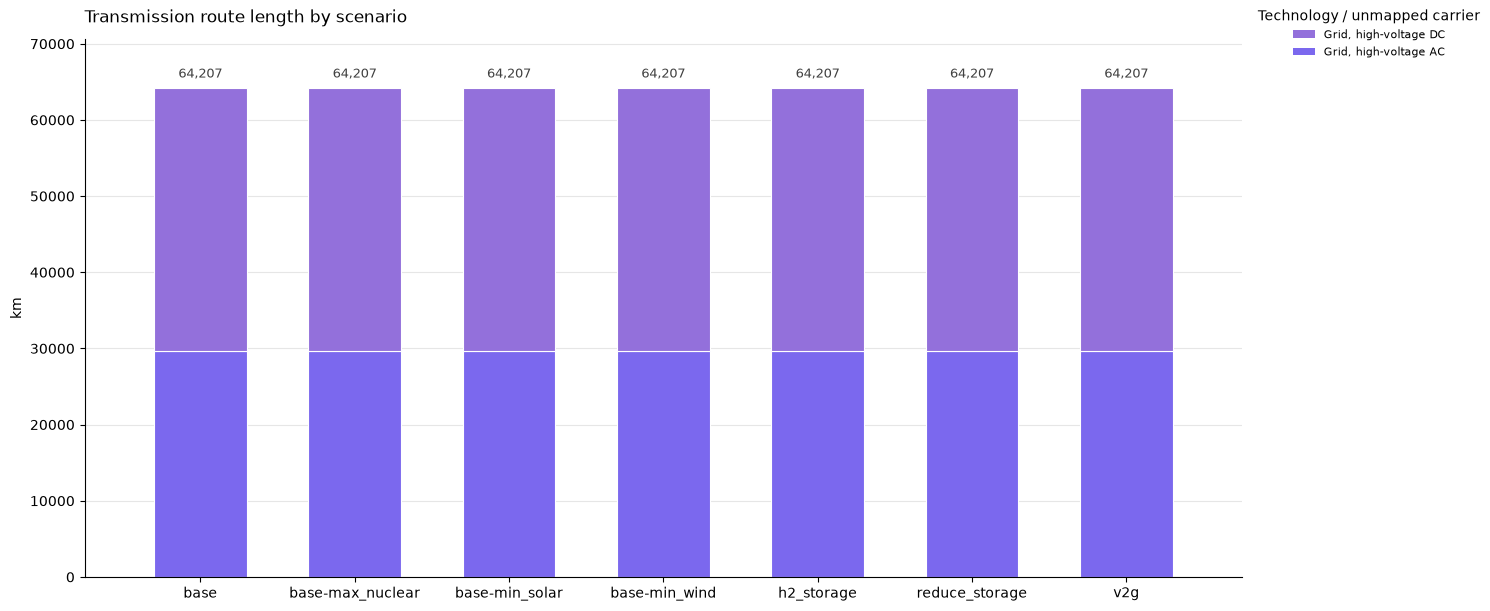

In [7]:
stacked_by_technology(
    segments=[
        ("route_length_km", False),
    ],
    unit="km",
    segment_labels=None,
    name="route_length_km",
)

## Costs

Solid = capex of the optimised expansion, hatched = operating costs (fuel,
VOM); nuclear is almost entirely opex on its existing fleet, everything else
is capex-dominated. The tiny negative heat-pump opex is an artifact of the
reverse-wired heat-pump links (see `scripts/build_pypsa_summary.py`).

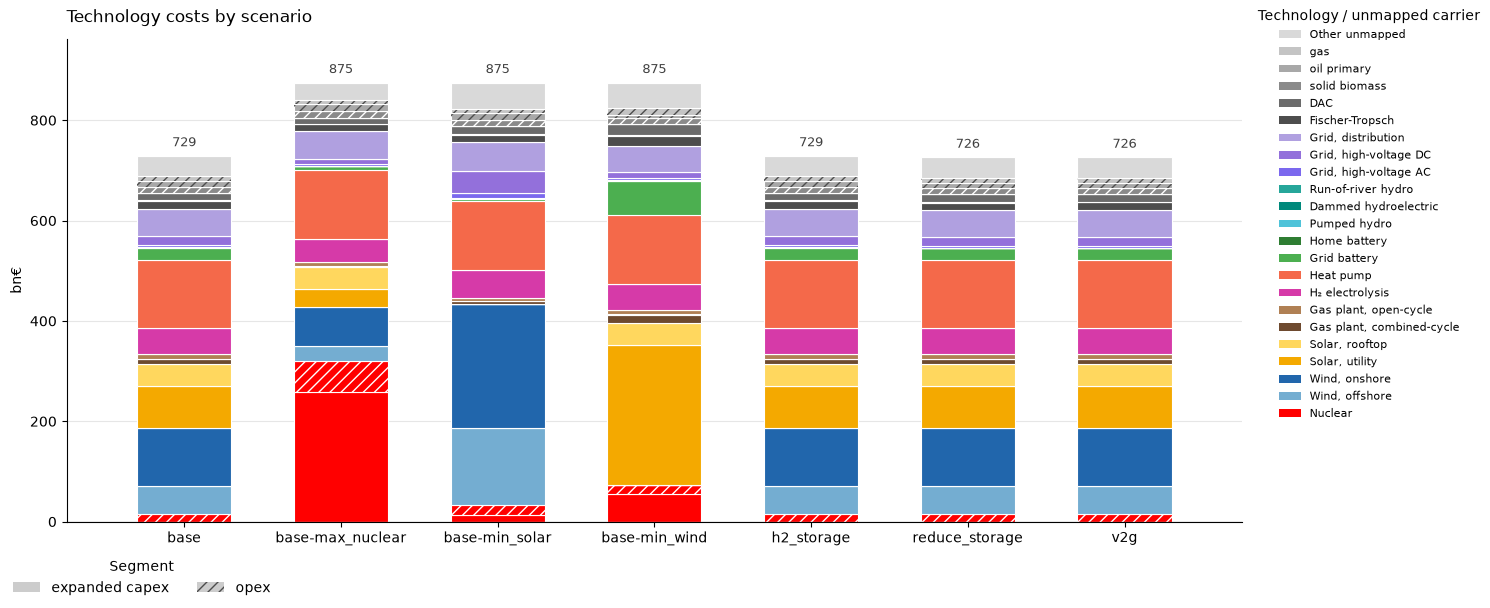

In [8]:
stacked_by_technology(
    segments=[
        ("expanded_capex_bn€", False),
        ("opex_bn€", True),
    ],
    unit="bn€",
    segment_labels=("Expanded capex", "Opex"),
    name="costs_bn_eur",
)